Importing libraries:

In [2]:
import pandas as pd

Load Dataset:

In [5]:
dataset=pd.read_csv("Electricity_Dataset.csv")

View Columns:

In [8]:
dataset.columns

Index(['Month', 'Temperature (°C)', 'Occupants', 'Appliances',
       'Previous_Usage', 'Current_Usage'],
      dtype='object')

Check the Null Values Present in the Dataset: 

In [11]:
dataset.isnull().sum()

Month               0
Temperature (°C)    0
Occupants           0
Appliances          0
Previous_Usage      0
Current_Usage       0
dtype: int64

Input/Output split:

In [14]:
independent=dataset.drop("Current_Usage",axis=1)

In [16]:
dependent=dataset["Current_Usage"]

Convert Nominal to Numerical datas:

In [19]:
independent=pd.get_dummies(independent,drop_first=True,dtype=int)

Train/Split data:

In [22]:
from sklearn.model_selection import train_test_split
X_train,X_test,y_train,y_test=train_test_split(independent,dependent,test_size=0.25,random_state=42)

Feature Scaling:

In [24]:
from sklearn.preprocessing import StandardScaler
sc=StandardScaler()
X_train=sc.fit_transform(X_train)
X_test=sc.transform(X_test)

Train a Model:

In [26]:
from sklearn.linear_model import Lasso
regressor=Lasso(alpha=2.0)
regressor.fit(X_train,y_train)

,"alpha alpha: float, default=1.0Constant that multiplies the L1 term, controlling regularizationstrength. `alpha` must be a non-negative float i.e. in `[0, inf)`.When `alpha = 0`, the objective is equivalent to ordinary leastsquares, solved by the :class:`LinearRegression` object. For numericalreasons, using `alpha = 0` with the `Lasso` object is not advised.Instead, you should use the :class:`LinearRegression` object.",2.0
,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"precompute precompute: bool or array-like of shape (n_features, n_features), default=FalseWhether to use a precomputed Gram matrix to speed upcalculations. The Gram matrix can also be passed as argument.For sparse input this option is always ``False`` to preserve sparsity.",False
,"copy_X copy_X: bool, default=TrueIf ``True``, X will be copied; else, it may be overwritten.",True
,"max_iter max_iter: int, default=1000The maximum number of iterations.",1000
,"tol tol: float, default=1e-4The tolerance for the optimization: if the updates are smaller or equal to``tol``, the optimization code checks the dual gap for optimality and continuesuntil it is smaller or equal to ``tol``, see Notes below.",0.0001
,"warm_start warm_start: bool, default=FalseWhen set to ``True``, reuse the solution of the previous call to fit asinitialization, otherwise, just erase the previous solution.See :term:`the Glossary <warm_start>`.",False
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive.",False
,"random_state random_state: int, RandomState instance, default=NoneThe seed of the pseudo random number generator that selects a randomfeature to update. Used when ``selection`` == 'random'.Pass an int for reproducible output across multiple function calls.See :term:`Glossary <random_state>`.",None
,"selection selection: {'cyclic', 'random'}, default='cyclic'If set to 'random', a random coefficient is updated every iterationrather than looping over features sequentially by default. This(setting to 'random') often leads to significantly faster convergenceespecially when tol is higher than 1e-4.",'cyclic'
Name,Type,Value


Model Evaluation:

In [31]:
y_pred=regressor.predict(X_test)

In [33]:
from sklearn.metrics import r2_score
r_score=r2_score(y_test,y_pred)
print(f"The model performance is {r_score}")

The model performance is 0.9541427810039178


Plot the Graph Actual vs Predicted:

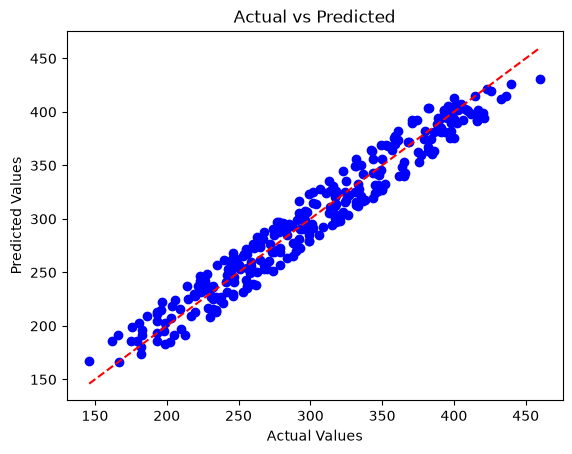

In [36]:
import matplotlib.pyplot as plt

plt.scatter(y_test, y_pred, color='blue')
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], color='red', linestyle='--')
plt.xlabel('Actual Values')
plt.ylabel('Predicted Values')
plt.title('Actual vs Predicted')
plt.show()